In [67]:
import os
os.environ['TF_ENABLE_ONEDNN_OPTS'] = '0'
import numpy as np 
import pandas as pd 
from PIL import Image
from sklearn.model_selection import train_test_split
import tensorflow as tf
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, RandomFlip, RandomRotation, RandomZoom, Flatten
from tensorflow.keras.activations import relu,linear
from tensorflow.keras.losses import SparseCategoricalCrossentropy
from tensorflow.keras.callbacks import EarlyStopping
from tensorflow.keras.optimizers import Adam
from sklearn.metrics import accuracy_score
RANDOM_STATE = 42

In [83]:
df = pd.read_csv("metadata_cleaned.csv")

X = np.load("images_greyscale.npy")
y = df['diagnostic'].to_numpy()
# print(y.shape, " ", X.shape)

X_train, X_, y_train , y_ = train_test_split(X, y, test_size=0.30, random_state= RANDOM_STATE)
X_cv, X_test, y_cv, y_test = train_test_split(X_, y_, test_size=0.50, random_state=RANDOM_STATE )


In [4]:
def eval_err(y, y_hat):

    m = len(y)
    neg = 0

    for i in range(m):
        if y[i] != y_hat[i]:
            neg+=1
        
    err = neg/m
    return err


In [ ]:




model = Sequential(
    [
    Dense(256, activation='relu', kernel_regularizer= tf.keras.regularizers.l2(0.0001), name="L1"),
    Dense(128, activation='relu', kernel_regularizer= tf.keras.regularizers.l2(0.0001), name= "L2"),
    Dense(1, activation='sigmoid', name= "L3")
    ]
    , name= "Simple_ANN"
 )

In [87]:
model.compile(
    loss = tf.keras.losses.BinaryCrossentropy(),
    optimizer= tf.keras.optimizers.Adam(0.001),
    metrics = ['accuracy']
)

# w_before = model.layers[1].get_weights()[0].copy() 


es = EarlyStopping(monitor='val_accuracy', patience=7, restore_best_weights=True)

history = model.fit(X_train, y_train, validation_data=(X_cv, y_cv),
                    epochs=50,
                    batch_size=32,
                    callbacks=[es])



# w_after = model.layers[1].get_weights()[0]
# print("Max weight change:", np.abs(w_after - w_before).max())

Epoch 1/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 6s 43ms/step - accuracy: 0.5087 - loss: 0.7602 - val_accuracy: 0.4957 - val_loss: 0.7152
Epoch 2/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 30ms/step - accuracy: 0.5006 - loss: 0.7293 - val_accuracy: 0.5043 - val_loss: 0.7113
Epoch 3/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 34ms/step - accuracy: 0.5199 - loss: 0.7173 - val_accuracy: 0.4957 - val_loss: 0.7193
Epoch 4/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.4975 - loss: 0.7082 - val_accuracy: 0.5565 - val_loss: 0.6960
Epoch 5/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 37ms/step - accuracy: 0.5311 - loss: 0.7021 - val_accuracy: 0.5014 - val_loss: 0.7023
Epoch 6/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 33ms/step - accuracy: 0.5205 - loss: 0.7042 - val_accuracy: 0.5681 - val_loss: 0.6941
Epoch 7/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 48ms/step - accuracy: 0.5261 - loss: 0.6988 - val_accuracy: 0.5043 - val_loss: 0.6992
Epoch 8/50
51/51 ━━━━━━━━━━━━━━━━━━━━ 2s 29ms/step - accuracy: 0.5454 - loss: 0.6989 - val_accuracy: 0.5217 - v

In [58]:
y_hat =model.predict(X_train)
y_pred = (y_hat >= 0.5).astype(int)
err = eval_err(y_train, y_hat)
print (err)
print(history.history['accuracy'])
print(history.history['val_accuracy'])

51/51 ━━━━━━━━━━━━━━━━━━━━ 1s 10ms/step
1.0
[0.4987562298774719, 0.5292288661003113, 0.518034815788269, 0.5174129605293274, 0.5342040061950684, 0.5267412662506104, 0.5466417670249939, 0.5379353165626526, 0.5391790866851807, 0.5441542267799377, 0.5466417670249939, 0.5273631811141968, 0.5609452724456787]
[0.5043478012084961, 0.4956521689891815, 0.4956521689891815, 0.5188405513763428, 0.49275362491607666, 0.5768116116523743, 0.52173912525177, 0.5420289635658264, 0.5043478012084961, 0.5623188614845276, 0.4956521689891815, 0.5507246255874634, 0.5652173757553101]


In [90]:
y_pred_probs = model.predict(X_test)
# 2. Convert probabilities to binary predictions (>= 0.5 becomes 1, else 0)
y_pred = (y_pred_probs >= 0.5).astype(int)

# 3. Calculate exact accuracy score
acc = accuracy_score(y_test, y_pred)
print(f"Calculated Test Accuracy: {acc * 100:.2f}%")



11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step 
Calculated Test Accuracy: 59.42%


In [9]:
ids = np.load("images_ids.npy")
print(ids[:10]) ,"\n" 
print(y[:10])


['PAT_1516_1765_530.png' 'PAT_46_881_939.png' 'PAT_1545_1867_547.png'
 'PAT_1989_4061_934.png' 'PAT_684_1302_588.png' 'PAT_1549_1882_230.png'
 'PAT_778_1471_835.png' 'PAT_117_179_983.png' 'PAT_1995_4080_695.png'
 'PAT_705_4015_413.png']
[0 1 0 0 1 0 1 1 0 0]


In [11]:

img_ids_npy = np.load('images_ids.npy', allow_pickle=True)
csv_ids = df['img_id'].values

print(len(img_ids_npy), len(csv_ids))                    # do the lengths even match?
print(np.array_equal(img_ids_npy, csv_ids))               # True only if every position matches, in order

2298 2298
True


In [19]:
model.summary()

print(y_pred_probs.min(), y_pred_probs.max(), y_pred_probs.mean(), y_pred_probs.std())

Model: "Simple_ANN"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ L1 (Dense)                      │ (None, 25)             │       102,425 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L2 (Dense)                      │ (None, 15)             │           390 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ L3 (Dense)                      │ (None, 1)              │            16 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 308,495 (1.18 MB)

 Trainable params: 102,831 (401.68 KB)

 Non-trainable params: 0 (0.00 B)

 Optimizer params: 205,664 (803.38 KB)

0.4643828 0.46438387 0.46438333 2.0745921e-07


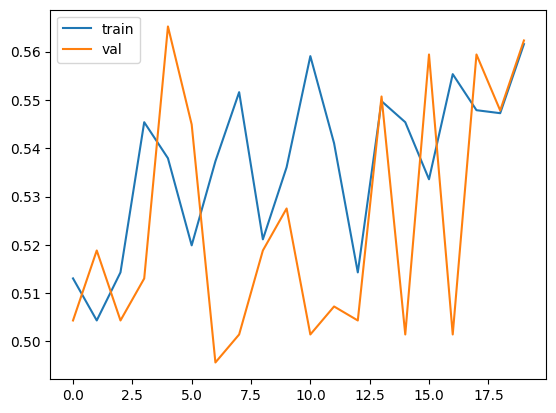

In [32]:
import matplotlib.pyplot as plt
plt.plot(history.history['accuracy'], label='train')
plt.plot(history.history['val_accuracy'], label='val')
plt.legend()
plt.show()

Mean: 0.543, Std: 0.017, Range: 0.525–0.568
